# Notebook 2 — Cluster-based Network Modeling (CNM)

Main reference: H. Li, D. Fernex, R. Semaan, J. Tan, M. Morzyński, B. R. Noack, *Cluster-based network model*, J. Fluid Mech. **906**, A21 (2021), arXiv:2001.02911.

**Idea.** Instead of writing reduced equations, we "summarize" the dynamics as a **network**:

- the **nodes** are the K-means centroids (representative states of the system);
- the **directed edges** are the transitions between clusters observed in the data;
- each edge has a **probability** $Q_{ij}$ and a **transition time** $T_{ij}$.

The modeled dynamics is a "constant-velocity flight" from one centroid to the next, like airplanes between airports. The model is **purely data-driven**: it does not use the equations of the system. By construction it stays close to the data and therefore never diverges.

**Contents** (all on the Lorenz system)

1. Ingredients: affiliation, direct transition matrix $\boldsymbol{Q}$, transition time matrix $\boldsymbol{T}$.
2. Data and clustering.
3. The matrices $\boldsymbol{Q}$ and $\boldsymbol{T}$ and the network.
4. Simulation of the CNM.
5. Validation: cluster probabilities and autocorrelation.
6. Effect of the number of clusters.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import CubicSpline
from sklearn.cluster import KMeans

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})

## 1. The ingredients of CNM

We start from $M$ snapshots $\boldsymbol{u}_m = \boldsymbol{u}(t_m)$ sampled with time step $\Delta t$ and clustered with K-means into $K$ clusters with centroids $\boldsymbol{c}_k$ (Notebook 1). The cluster index along the trajectory, $k(t)$, is piecewise constant and jumps when the state enters a new cluster.

**Residence times.** Let $t_n$ be the jump instants. The residence time in the $n$-th visited cluster is $\tau_n = t_{n+1} - t_n$.

**Direct transitions.** If after $t_n$ the state is in cluster $j$ and after $t_{n+1}$ in cluster $i$, we count one transition $j \to i$. The **transition time** is the distance between the centers of the two residences:

$$\tau_{ij} = \frac{\tau_n + \tau_{n+1}}{2}.$$

These quantities give the two matrices of the model:

$$Q_{ij} = \frac{n_{ij}}{n_j}, \qquad T_{ij} = \langle \tau_{ij} \rangle ,$$

where $n_{ij}$ is the number of transitions $j \to i$, $n_j = \sum_i n_{ij}$, and $\langle\cdot\rangle$ is the average over all transitions $j \to i$. By definition $Q_{ii} = 0$: only jumps to a **different** cluster count. Each column of $\boldsymbol{Q}$ sums to 1.

**Simulation.** Starting from centroid $k_0$ at time $t_0$, the next cluster $k_1$ is drawn with probability $Q_{k_1 k_0}$; it is reached at time $t_1 = t_0 + T_{k_1 k_0}$; and so on. Between two visits the state moves at constant velocity:

$$\boldsymbol{u}(t) = \alpha_n(t)\,\boldsymbol{c}_{k_n} + \big[1-\alpha_n(t)\big]\,\boldsymbol{c}_{k_{n+1}}, \qquad \alpha_n = \frac{t_{n+1} - t}{t_{n+1} - t_n}.$$

In [2]:
def affiliation(U, C):
    # index of the nearest centroid for each row of U
    d2 = (U ** 2).sum(1)[:, None] - 2 * U @ C.T + (C ** 2).sum(1)[None, :]
    return d2.argmin(axis=1)

def cnm_fit(labels, dt, K):
    # estimate Q[i, j] (prob. j -> i) and T[i, j] (time j -> i) from the cluster sequence
    jumps = np.where(np.diff(labels) != 0)[0] + 1
    starts = np.r_[0, jumps]
    seq = labels[starts]                                   # visited clusters, in order
    tau = np.diff(np.r_[starts, len(labels)]) * dt         # residence times
    seq, tau = seq[1:-1], tau[1:-1]                        # the first and last residences are truncated
    t_centers = (starts[1:-1] * dt + 0.5 * tau)            # centers of the residences

    n = np.zeros((K, K))
    T_sum = np.zeros((K, K))
    for j, i, tj, ti in zip(seq[:-1], seq[1:], tau[:-1], tau[1:]):
        n[i, j] += 1
        T_sum[i, j] += 0.5 * (tj + ti)
    Q = n / np.maximum(n.sum(axis=0, keepdims=True), 1)
    T = T_sum / np.maximum(n, 1)
    return Q, T, seq, tau, t_centers

def cnm_probability(ks, seq, tau, K):
    # eq. (2.16): each visit to cluster i lasts, on average, the mean residence time observed in the data
    tau_mean = np.bincount(seq, weights=tau, minlength=K) / np.maximum(np.bincount(seq, minlength=K), 1)
    p = np.bincount(ks, minlength=K) * tau_mean
    return p / p.sum()

def cnm_simulate(Q, T, k0, t0, n_transitions, rng):
    ks, ts = [k0], [t0]
    for _ in range(n_transitions):
        j = ks[-1]
        i = rng.choice(len(Q), p=Q[:, j])
        ks.append(i)
        ts.append(ts[-1] + T[i, j])
    return np.array(ks), np.array(ts)

def cnm_trajectory(C, ks, ts, t_grid, spline=False):
    # CNM state on a time grid: linear interpolation (eq. 2.20) or cubic spline
    if spline:
        return CubicSpline(ts, C[ks])(t_grid)
    return np.column_stack([np.interp(t_grid, ts, C[ks, d]) for d in range(C.shape[1])])

## 2. Lorenz system: data and clustering

$$\dot x = \sigma(y-x), \qquad \dot y = x(\rho - z) - y, \qquad \dot z = xy - bz,$$

with $\sigma = 10$, $\rho = 28$, $b = 8/3$, sampled with $\Delta t = 0.005$ (paper, §2.6). We use $M = 10^5$ snapshots (the paper uses $10^6$) and $K = 10$ clusters. To make the matrices easier to read, we sort the clusters by the $x$ coordinate of their centroid: the first ones lie on the wing around $F^- = (-\sqrt{72}, -\sqrt{72}, 27)$, the last ones on the wing around $F^+$.

snapshots: (100000, 3)


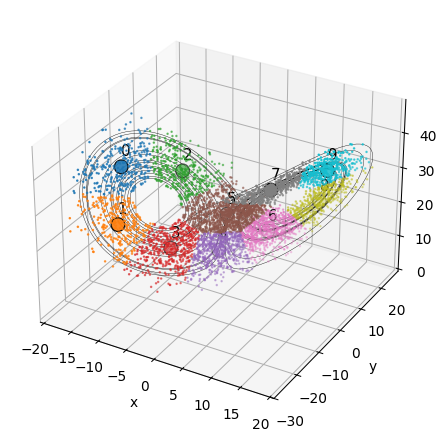

In [3]:
def lorenz(t, s, sigma=10.0, rho=28.0, b=8.0 / 3.0):
    x, y, z = s
    return [sigma * (y - x), x * (rho - z) - y, x * y - b * z]

dt = 0.005
sol = solve_ivp(lorenz, [0, 520], [1.0, 1.0, 1.0], t_eval=np.arange(0, 520, dt), rtol=1e-9, atol=1e-9)
X = sol.y.T[int(20 / dt):]                      # discard the transient
t = np.arange(len(X)) * dt
print("snapshots:", X.shape)

K = 10
km = KMeans(K, n_init=10, random_state=0).fit(X)
C = km.cluster_centers_[np.argsort(km.cluster_centers_[:, 0])]
lab = affiliation(X, C)

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
ax.plot(*X[:4000].T, "k", lw=0.3)
ax.scatter(*X[::20].T, c=lab[::20], cmap="tab10", s=1)
ax.scatter(*C.T, c=range(K), cmap="tab10", s=120, edgecolor="k")
for k in range(K):
    ax.text(*C[k] + [0, 0, 3], str(k), fontsize=12)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
plt.show()

## 3. The matrices $\boldsymbol{Q}$ and $\boldsymbol{T}$

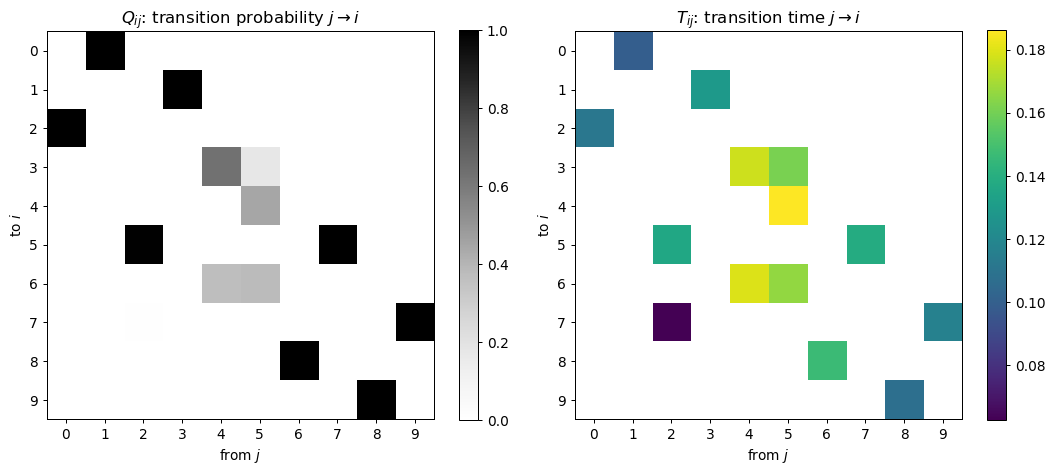

observed transitions: 3638;  network edges: 14 out of 90 possible
  from cluster 2 the state can go to 5 (Q=0.99), 7 (Q=0.01)
  from cluster 4 the state can go to 3 (Q=0.63), 6 (Q=0.37)
  from cluster 5 the state can go to 3 (Q=0.17), 4 (Q=0.45), 6 (Q=0.38)


In [4]:
Q, T, seq, tau, t_centers = cnm_fit(lab, dt, K)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
im = ax[0].imshow(Q, cmap="Greys", vmin=0, vmax=1); plt.colorbar(im, ax=ax[0])
ax[0].set_title("$Q_{ij}$: transition probability $j \\to i$")
Tm = np.ma.masked_where(Q == 0, T)
im = ax[1].imshow(Tm, cmap="viridis"); plt.colorbar(im, ax=ax[1])
ax[1].set_title("$T_{ij}$: transition time $j \\to i$")
for a in ax:
    a.set_xlabel("from $j$"); a.set_ylabel("to $i$"); a.set_xticks(range(K)); a.set_yticks(range(K)); a.grid(False)
plt.tight_layout(); plt.show()

print(f"observed transitions: {len(seq) - 1};  network edges: {np.count_nonzero(Q)} out of {K * (K - 1)} possible")
for j in range(K):
    out = np.nonzero(Q[:, j])[0]
    if len(out) > 1:
        print(f"  from cluster {j} the state can go to " + ", ".join(f"{i} (Q={Q[i, j]:.2f})" for i in out))

The network is very **sparse**: almost every cluster has a single possible successor, i.e. the dynamics is deterministic from cell to cell. The only "choices" happen in the few clusters with more than one exit, in the region between the two wings (the *flipper* clusters of Kaiser et al. 2014): this is where the system decides whether to make another loop on the same wing or to switch to the other one. It is the same feature that makes the Lorenz system chaotic.

We draw the network on the $(x, z)$ plane: the arrow width is proportional to $Q_{ij}$.

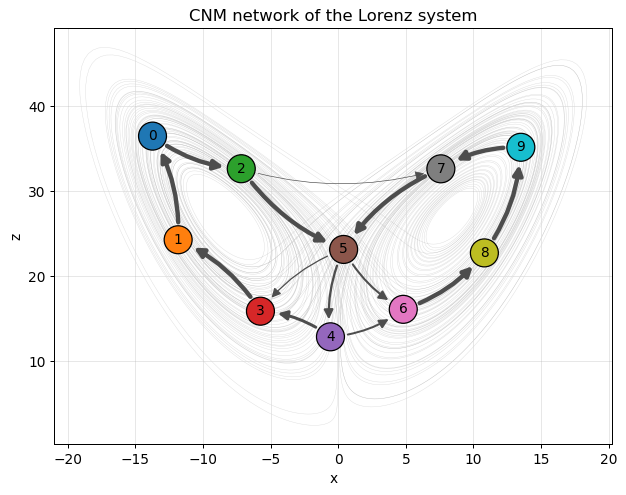

In [5]:
def draw_network(ax, pos, Q, rad=0.15):
    K = len(Q)
    for j in range(K):
        for i in range(K):
            if Q[i, j] > 0:
                ax.annotate("", xy=pos[i], xytext=pos[j],
                            arrowprops=dict(arrowstyle="-|>", lw=0.5 + 3 * Q[i, j], color="0.3",
                                            shrinkA=14, shrinkB=14, mutation_scale=15,
                                            connectionstyle=f"arc3,rad={rad}"))
    ax.scatter(*pos.T, s=500, c=range(K), cmap="tab10", vmin=0, vmax=9, edgecolor="k", zorder=3)
    for k in range(K):
        ax.text(*pos[k], str(k), ha="center", va="center", fontsize=11, zorder=4)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(X[:20000, 0], X[:20000, 2], color="0.85", lw=0.3)
draw_network(ax, C[:, [0, 2]], Q)
ax.set_xlabel("x"); ax.set_ylabel("z"); ax.set_title("CNM network of the Lorenz system")
plt.show()

## 4. Simulating the CNM

We simulate $20\,000$ transitions (as in the paper), starting from the first cluster visited in the data. For visualization we also use a cubic spline between visits, as in Fig. 6b of the paper; for the statistics we use the linear interpolation of eq. (2.20).

time simulated by the CNM: 2743 time units (548544 samples)


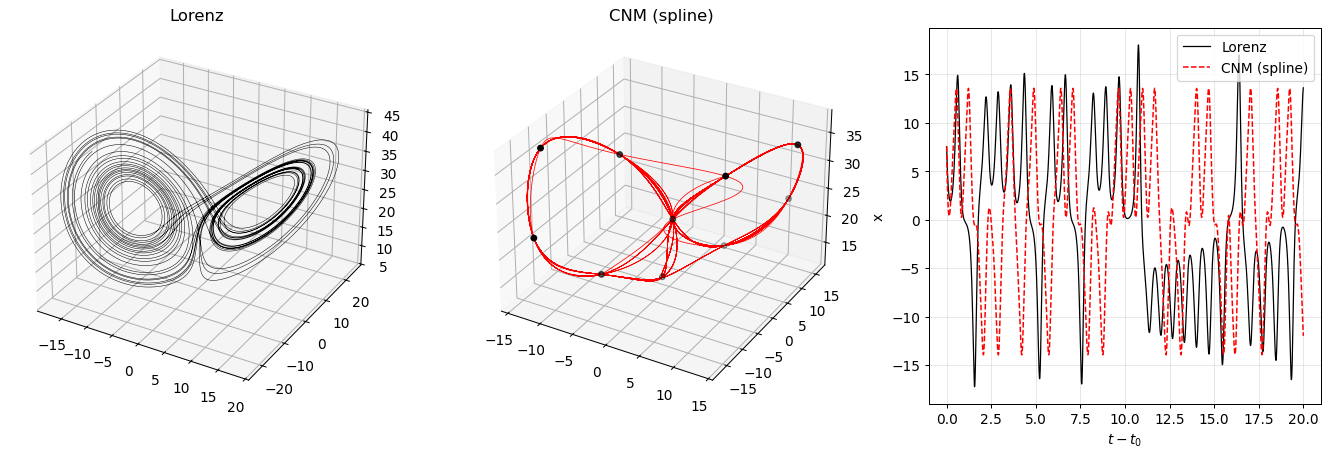

In [6]:
rng = np.random.default_rng(1)
ks, ts = cnm_simulate(Q, T, seq[0], t_centers[0], 20_000, rng)
t_grid = np.arange(ts[0], ts[-1], dt)
X_cnm = cnm_trajectory(C, ks, ts, t_grid)                  # linear
n_show = 200
X_spl = cnm_trajectory(C, ks[:n_show], ts[:n_show], np.arange(ts[0], ts[n_show - 1], dt), spline=True)
print(f"time simulated by the CNM: {ts[-1] - ts[0]:.0f} time units ({len(t_grid)} samples)")

fig = plt.figure(figsize=(15, 5))
ax = fig.add_subplot(131, projection="3d")
ax.plot(*X[:6000].T, "k", lw=0.4); ax.set_title("Lorenz")
ax = fig.add_subplot(132, projection="3d")
ax.plot(*X_spl[:6000].T, "r", lw=0.6); ax.scatter(*C.T, c="k", s=20); ax.set_title("CNM (spline)")
ax = fig.add_subplot(133)
i0 = int(t_centers[0] / dt)
tt = np.arange(0, 20, dt)
ax.plot(tt, X[i0:i0 + len(tt), 0], "k", lw=1, label="Lorenz")
ax.plot(tt[:len(X_spl)], X_spl[:len(tt), 0], "r--", lw=1.2, label="CNM (spline)")
ax.set_xlabel("$t - t_0$"); ax.set_ylabel("x"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

The CNM reproduces the oscillations on each wing and the jumps from one wing to the other, but **not** the growth of the oscillation amplitude: with 10 clusters each wing is represented by only 4 centroids, which resolve the phase but not the amplitude. Moreover, the sequence of jumps is stochastic, so the two trajectories separate after a few oscillations. The same happens to two trajectories of the true system starting close to each other: the largest Lyapunov exponent is about $0.9$.

The correct comparison is therefore **statistical**.

## 5. Validation

We compare:

- **Cluster probabilities**: fraction of time spent in each cluster. For the CNM we use eq. (2.16) of the paper: $p_i = \sum \tau_i / T_0$, i.e. (number of visits to cluster $i$) $\times$ (mean residence time in $i$) divided by the total time.
- **Autocorrelation** of the fluctuations, $R(\tau) = \langle \boldsymbol{u}'(t)\cdot\boldsymbol{u}'(t+\tau)\rangle$, normalized by the data variance: it contains the fluctuation level ($R(0)$) and the frequency content.

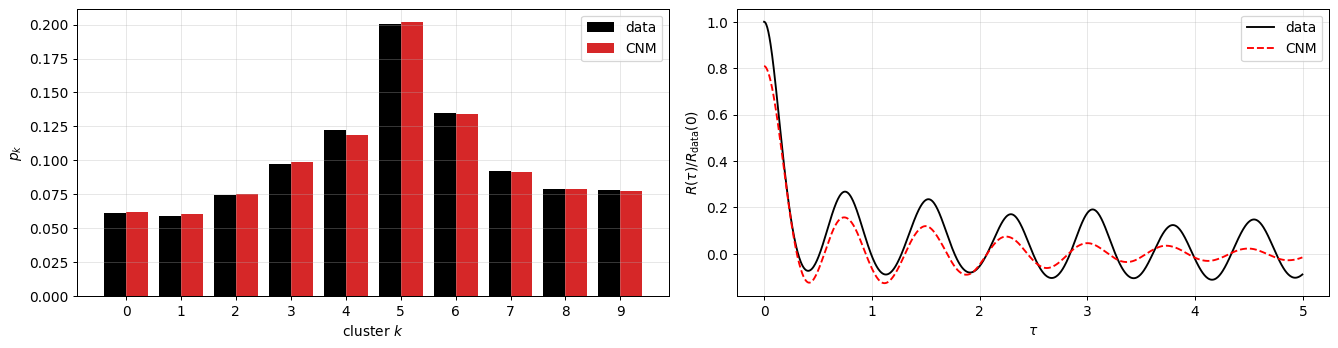

mean relative error on p_k (CNM): 1.2%


In [7]:
def autocorr(U, n_lags, mean):
    # unbiased autocorrelation of U - mean, computed with the FFT
    V = U - mean
    n = len(V)
    F = np.fft.rfft(V, 2 * n, axis=0)
    r = np.fft.irfft(np.abs(F) ** 2, axis=0)[:n_lags].sum(axis=1)
    return r / (n - np.arange(n_lags))

# cluster probabilities
p_data = np.bincount(lab, minlength=K) / len(lab)
p_cnm = cnm_probability(ks, seq, tau, K)

# autocorrelation
mean = X.mean(axis=0)
n_lags = int(5 / dt)
R_data = autocorr(X, n_lags, mean)
R_cnm = autocorr(X_cnm, n_lags, mean)
lags = np.arange(n_lags) * dt

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].bar(np.arange(K) - 0.2, p_data, 0.4, color="k", label="data")
ax[0].bar(np.arange(K) + 0.2, p_cnm, 0.4, color="tab:red", label="CNM")
ax[0].set_xticks(range(K)); ax[0].set_xlabel("cluster $k$"); ax[0].set_ylabel("$p_k$"); ax[0].legend()
ax[1].plot(lags, R_data / R_data[0], "k", label="data")
ax[1].plot(lags, R_cnm / R_data[0], "r--", label="CNM")
ax[1].set_xlabel(r"$\tau$"); ax[1].set_ylabel(r"$R(\tau) / R_{\rm data}(0)$"); ax[1].legend()
plt.tight_layout(); plt.show()

print("mean relative error on p_k (CNM): {:.1%}".format(np.mean(np.abs(p_cnm - p_data) / p_data)))



- the CNM reproduces the **cluster probabilities** accurately (mean relative error of the order of 1%). The residual error depends on the length of the simulation and on the assumption of constant transition times $T_{ij}$;
- the CNM reproduces well the dominant **frequency** of the autocorrelation (the period of one loop around a wing). The fluctuation level $R(0)$ is underestimated because the centroids are averages and "cut" the larger oscillations. Moreover, the oscillations of $R(\tau)$ decay faster than in the data: the random choice in the *flipper* clusters and the constant transition times make the model lose memory of the phase.

## 6. Effect of the number of clusters

With more clusters the cells are smaller and the CNM resolves the oscillation amplitude better: the fluctuation level $R(0)$ gets closer to that of the data. The price is a larger network, with more parameters ($Q_{ij}$, $T_{ij}$) to estimate from the same amount of data. Note, however, that the long-time correlation does not improve: this is a limitation of the model structure (first-order Markov transitions, constant times), not of its resolution.

K =  10: network edges =   15, R(0)/R_data(0) = 0.81
K =  30: network edges =   67, R(0)/R_data(0) = 0.93
K = 100: network edges =  262, R(0)/R_data(0) = 0.98


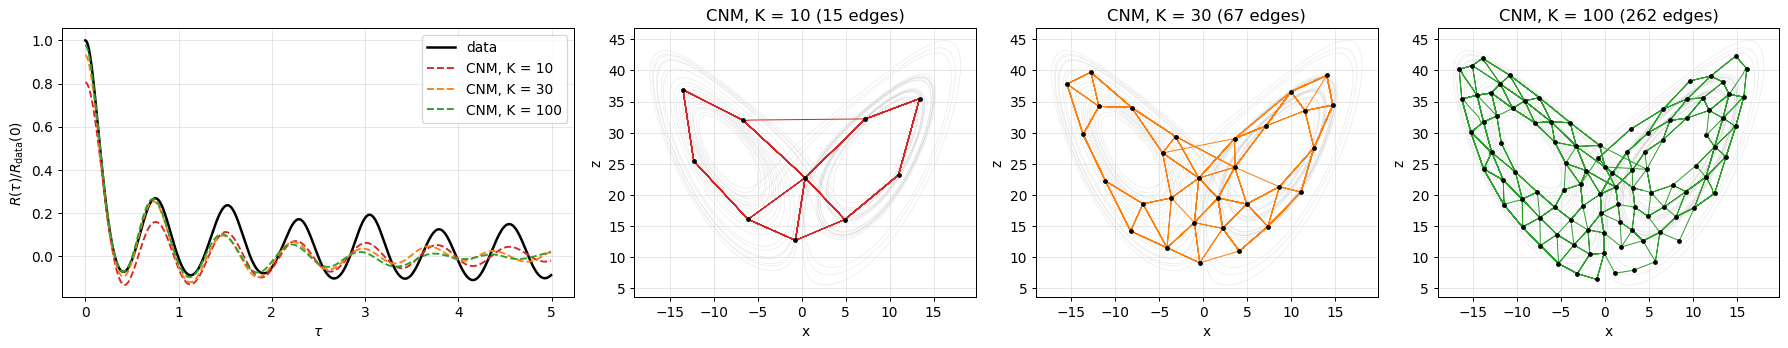

In [16]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4), gridspec_kw={"width_ratios": [1.5, 1, 1, 1]})
ax[0].plot(lags, R_data / R_data[0], "k", lw=2, label="data")
for a, K_, col in zip(ax[1:], [10, 30, 100], ["tab:red", "tab:orange", "tab:green"]):
    km_ = KMeans(K_, n_init=4, random_state=0).fit(X)
    C_ = km_.cluster_centers_
    lab_ = affiliation(X, C_)
    Q_, T_, seq_, tau_, tc_ = cnm_fit(lab_, dt, K_)
    ks_, ts_ = cnm_simulate(Q_, T_, seq_[0], tc_[0], 20_000, np.random.default_rng(1))
    X_ = cnm_trajectory(C_, ks_, ts_, np.arange(ts_[0], ts_[-1], dt))
    R_ = autocorr(X_, n_lags, mean)
    ax[0].plot(lags, R_ / R_data[0], "--", color=col, label=f"CNM, K = {K_}")
    a.plot(X[:6000, 0], X[:6000, 2], color="0.85", lw=0.3)
    a.plot(X_[:6000, 0], X_[:6000, 2], color=col, lw=0.8)
    a.scatter(C_[:, 0], C_[:, 2], c="k", s=8, zorder=3)
    a.set_title(f"CNM, K = {K_} ({np.count_nonzero(Q_)} edges)"); a.set_xlabel("x"); a.set_ylabel("z")
    print(f"K = {K_:3d}: network edges = {np.count_nonzero(Q_):4d}, R(0)/R_data(0) = {R_[0] / R_data[0]:.2f}")
ax[0].set_xlabel(r"$\tau$"); ax[0].set_ylabel(r"$R(\tau)/R_{\rm data}(0)$"); ax[0].legend()
plt.tight_layout(); plt.show()

## 7. Summary

| | CNM |
|---|---|
| **Input** | time-resolved snapshots, no equations |
| **Parameters** | $K$ centroids, matrices $\boldsymbol{Q}$ and $\boldsymbol{T}$ ($K \times K$, sparse) |
| **Pros** | simple, automatable, robust (never diverges), interpretable as a network, same recurrences as the data |
| **Cons** | no extrapolation beyond the data; resolution limited by the number of clusters; constant transition times; no link to the equations |

**Extensions** (further reading):

- higher-order CNM: the transition depends on the last $L$ visited clusters (Fernex, Noack & Semaan, *Sci. Adv.* 2021);
- *extended* CNM: clustering on subspaces for turbulent flows (Colanera et al., *TCFD* 2024);
- *orbital* CNM: spatio-temporal centroids (Colanera et al., 2025);
- *cluster globally, model locally*: local linear models around the centroids (Deng et al., 2024).

**Notebook 3** uses the same cluster partition of the Lorenz attractor but, inside each cell, builds a reduced-order model **from the governing equations** (Galerkin): the ql-ROM.
